# Лабораторная работа 3. Векторы и матрицы

В этой работе реализуются базовые операции линейной алгебры без использования готовых функций `numpy.linalg` внутри собственных алгоритмов.

Цель работы: изучить внутреннюю реализацию операций над векторами и матрицами, методы вычисления определителя и обратной матрицы, а также оценить влияние вычислительной сложности и обусловленности задачи.

Запускайте ячейки сверху вниз. Места для самостоятельной реализации отмечены `TODO`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter

np.set_printoptions(precision=5, suppress=True)
plt.rcParams['figure.figsize'] = (8, 4.5)

## 1. Скалярное произведение

Для двух векторов одинаковой размерности:

$$a\cdot b=\sum_i a_i b_i$$

Реализуем операцию вручную одним циклом и сравним результат с NumPy.

In [2]:
def dot(a, b):
    # TODO: проверить размерности
    # TODO: реализовать через цикл
    if len(a) != len(b):
        raise ValueError("Размерность векторов не совпадает")

    ans = 0
    for i in range(len(a)):
        ans += a[i] * b[i]

    return ans

## 2. Векторное произведение

Векторное произведение определено только для трёхмерных векторов:

$$a\times b=(a_2b_3-a_3b_2, a_3b_1-a_1b_3, a_1b_2-a_2b_1)$$

Геометрически длина полученного вектора равна площади параллелограмма, построенного на векторах.

In [3]:
def cross(a, b):
    # TODO: реализовать формулу вручную
    if len(a) != len(b):
        raise ValueError("Размерность векторов не совпадает")
    if len(a) != 3:
        raise ValueEror("Вектора должны быть трехмерными")

    return [a[1] * b[2] - a[2] * b[1], a[2] * b[0] - a[0] * b[2], a[0] * b[1] - a[1] * b[0]]

## 3. Умножение матриц

Элемент результирующей матрицы:

$$c_{ij}=\sum_k a_{ik}b_{kj}$$

Количество операций растёт как $O(n^3)$.

In [4]:
def matmul(A, B):
    # TODO: реализовать тройным циклом
    if len(A[0]) != len(B):
        raise ValueError("Размерности матриц не подходят для умножения")

    ans = np.zeros((len(A), len(B[0])))
    for i in range(len(A)):
        for j in range(len(B[0])):
            for k in range(len(A[0])):
                ans[i][j] += A[i][k] * B[k][j]

## 4. Определитель матрицы

Используем исключение Гаусса с частичным выбором ведущего элемента.

Для каждого шага k от 1 до n-1:

1. **Поиск главного элемента (Частичный выбор):**
   В текущем столбце k ищется строка m (где m ≥ k), содержащая максимальный по модулю элемент среди элементов от диагонали и ниже:
   $\vert{}A_{mk}\vert{} = \max_{i = k, \dots, n} \vert{}A_{ik}\vert{}$

2. **Проверка на нулевой столбец:**
   Если $(\vert{}A_{mk}\vert{} \approx 0)$, то все элементы под диагональю в этом столбце уже равны нулю. Переходим к следующему шагу цикла `continue`.

3. **Перестановка строк:**
   Если индекс строки с максимумом m ≠ k, то строки k и m меняются местами целиком:
   $A_k \leftrightarrow A_m$

4. **Исключение элементов под диагональю:**
   Для каждой строки i от k+1 до n:
   * Вычисляется ведущий коэффициент (множитель):
     $\text{coef}_{ik} = \frac{A_{ik}}{A_{kk}}$
   * Из строки i вычитается строка k, умноженная на коэффициент. Модификация выполняется **строго для столбцов от k до n**, чтобы не производить лишних вычислений над уже зануленными элементами:
     $A_{ij} \leftarrow A_{ij} - A_{kj} \cdot \text{coef}_{ik} \quad \text{для} \ j = k, k+1, \dots, n$

Важно: перестановка строк меняет знак определителя.

Пример работы алгоритма:
$$
A = \begin{pmatrix} 2 & 4 & -2 \\ 4 & 9 & -3 \\ -2 & -3 & 7 \end{pmatrix}
$$

**Шаг 1 ($k=1$):** Поиск максимума в 1-м столбце $\max(|2|, |4|, |-2|) = 4 \implies$ перестановка строк $1 \leftrightarrow 2$:

$$
\sim \begin{pmatrix} 4 & 9 & -3 \\ 2 & 4 & -2 \\ -2 & -3 & 7 \end{pmatrix}
$$

Исключение под диагональю: строка $2 \leftarrow \text{строка } 2 - 0.5 \cdot \text{строка } 1$; строка $3 \leftarrow \text{строка } 3 - (-0.5) \cdot \text{строка } 1$:

$$
\sim \begin{pmatrix} 4 & 9 & -3 \\ 0 & -0.5 & -0.5 \\ 0 & 1.5 & 5.5 \end{pmatrix}
$$

**Шаг 2 ($k=2$):** Поиск максимума во 2-м столбце ниже диагонали $\max(|-0.5|, |1.5|) = 1.5 \implies$ перестановка строк $2 \leftrightarrow 3$:

$$
\sim \begin{pmatrix} 4 & 9 & -3 \\ 0 & 1.5 & 5.5 \\ 0 & -0.5 & -0.5 \end{pmatrix}
$$

Исключение под диагональю: строка $3 \leftarrow \text{строка } 3 - \left(-\frac{1}{3}\right) \cdot \text{строка } 2$:

$$
\sim \begin{pmatrix} 4 & 9 & -3 \\ 0 & 1.5 & 5.5 \\ 0 & 0 & \frac{4}{3} \end{pmatrix}
$$


In [5]:
def determinant(A, tol=1e-12):
    # TODO: метод Гаусса
    A = A.astype(float, copy=True) 
    n, m = A.shape
    swaps = 0
    
    if m != n:
        raise ValueError("Матрица должна быть квадратной")

    for k in range(n - 1):
        max_row_idx = k + np.argmax(np.abs(A[k:, k]))  # Ищем максимальный по модулю элемент в k-ом столбце ниже главной диагонале

        if np.isclose(A[max_row_idx, k], tol):
            return 0

        if max_row_idx != k:
            swaps += 1
            A[[max_row_idx, k]] = A[[k, max_row_idx]]  # Меняем строки местами

        for i in range(k + 1, n):
            coef_m_ik = A[i, k] / A[k, k]
            # A[i] -= A[k] *  coef_m_ik
            # Оптимизация:
            A[i, k:] -= coef_m_ik * A[k, k:]
    return  (-1) ** swaps * np.prod(np.diagonal(A))

In [6]:
A = np.array([
    [16, 21, 15, 23, 19],
    [6, 13, 24, 33, 49],
    [62, 90, 18, 25, 32],
    [-3, 100, -100, 200, 202],
    [1, 5, -10, -31, -2]
])

assert np.allclose(determinant(A), np.linalg.det(A))

## 5. Обратная матрица к матрице

Обратная матрица находится методом Жордана–Гаусса:

$$[A|E]\rightarrow[E|A^{-1}]$$

1. **Инициализация:** 
   Создать расширенную матрицу размера $n \times 2n$, приписав справа единичную матрицу: $[A \mid E]$.

2. **Главный цикл:** Для каждого столбца $k$ от $0$ до $n-1$:
   * **Выбор главного элемента:** Найти строку $p \ge k$ с максимальным по модулю элементом в столбце $k$. Если он близок к нулю — матрица вырождена, стоп.
   * **Перестановка:** Поменять местами строку $k$ и строку $p$.
   * **Нормализация:** Разделить всю строку $k$ на ведущий элемент $A_{k,k}$, чтобы получить $A_{k,k} = 1$.
   * **Исключение:** Для всех строк $i \neq k$ вычесть из строки $i$ строку $k$, умноженную на коэффициент $A_{i,k}$, чтобы занулить весь столбец $k$ выше и ниже диагонали.

3. **Результат:** 
   Выделить правую половину расширенной матрицы (столбцы от $n$ до $2n-1$). Это и есть $A^{-1}$.


Пример работы алгоритма:

Дана исходная матрица:
$$A = \begin{pmatrix} 2 & 1 & 3 \\ 1 & 1 & 1 \\ 0 & 2 & 1 \end{pmatrix}$$

***Шаг 1*** Формирование расширенной матрицы
Записываем матрицу $A$ и приписываем к ней справа единичную матрицу $E$:
$$\begin{pmatrix} A \mid E \end{pmatrix} = \left(\begin{array}{ccc|ccc} \mathbf{2} & 1 & 3 & 1 & 0 & 0 \\  1 & 1 & 1 & 0 & 1 & 0 \\  0 & 2 & 1 & 0 & 0 & 1 \end{array}\right)$$

***Шаг 2*** Обработка 1-го столбца ($k=0$)
Ведущий элемент: $A_{0,0} = 2$.

1. **Нормализация 1-й строки**: Делим всю строку 1 на $2$, чтобы получить единицу на главной диагонали:
$$\sim \left(\begin{array}{ccc|ccc} \mathbf{1} & 0.5 & 1.5 & 0.5 & 0 & 0 \\  1 & 1 & 1 & 0 & 1 & 0 \\  0 & 2 & 1 & 0 & 0 & 1 \end{array}\right)$$

2. **Обнуление столбца под ведущей единицей**: Из второй строки вычитаем первую ($R_1 \leftarrow R_1 - 1 \cdot R_0$). В третьей строке уже стоит $0$:
$$\sim \left(\begin{array}{ccc|ccc} 1 & 0.5 & 1.5 & 0.5 & 0 & 0 \\  \mathbf{0} & \mathbf{0.5} & \mathbf{-0.5} & \mathbf{-0.5} & \mathbf{1} & \mathbf{0} \\  0 & 2 & 1 & 0 & 0 & 1 \end{array}\right)$$

***Шаг 3*** Обработка 2-го столбца ($k=1$)
Ведущий элемент: новое значение на диагонали $A_{1,1} = 0.5$.

1. **Нормализация 2-й строки**: Умножаем строку 2 на $2$:
$$\sim \left(\begin{array}{ccc|ccc} 1 & 0.5 & 1.5 & 0.5 & 0 & 0 \\  0 & \mathbf{1} & -1 & -1 & 2 & 0 \\  0 & 2 & 1 & 0 & 0 & 1 \end{array}\right)$$

2. **Обнуление столбца выше и ниже ведущей единицы**:
   * Из 1-й строки вычитаем 2-ю строку, умноженную на $0.5$ 
   * Из 3-й строки вычитаем 2-ю строку, умноженную на $2$
$$\sim \left(\begin{array}{ccc|ccc} 1 & \mathbf{0} & 2 & 1 & -1 & 0 \\  0 & 1 & -1 & -1 & 2 & 0 \\  0 & \mathbf{0} & \mathbf{3} & \mathbf{2} & \mathbf{-4} & \mathbf{1} \end{array}\right)$$

***Шаг 4*** Обработка 3-го столбца ($k=2$)
Ведущий элемент: новое значение на диагонали $A_{2,2} = 3$.

1. **Нормализация 3-й строки**: Делим третью строку на $3$:
$$\sim \left(\begin{array}{ccc|ccc} 1 & 0 & 2 & 1 & -1 & 0 \\  0 & 1 & -1 & -1 & 2 & 0 \\  0 & 0 & \mathbf{1} & 2/3 & -4/3 & 1/3 \end{array}\right)$$

2. **Обнуление столбца выше ведущей единицы**:
   * Из 1-й строки вычитаем 3-ю строку, умноженную на $2$
   * Ко 2-й строке прибавляем 3-ю строку
$$\sim \left(\begin{array}{ccc|ccc} 1 & 0 & \mathbf{0} & \mathbf{-1/3} & \mathbf{5/3} & \mathbf{-2/3} \\  0 & 1 & \mathbf{0} & \mathbf{-1/3} & \mathbf{2/3} & \mathbf{1/3} \\  0 & 0 & 1 & 2/3 & -4/3 & 1/3 \end{array}\right)$$


***Результат***
Левая часть превратилась в единичную матрицу $E$. В правой части находится искомая обратная матрица $A^{-1}$:

$$A^{-1} = \begin{pmatrix} -1/3 & 5/3 & -2/3 \\ -1/3 & 2/3 & 1/3 \\ 2/3 & -4/3 & 1/3 \end{pmatrix} = \frac{1}{3} \begin{pmatrix} -1 & 5 & -2 \\ -1 & 2 & 1 \\ 2 & -4 & 1 \end{pmatrix}$$


In [7]:
def inverse(A, tol=1e-12):
    # TODO: расширенная матрица и преобразования строк
    A = A.astype(float, copy=True) 
    n = A.shape[0]

    if len(A) != len(A[0]):
        raise ValueError("Обратную матрицу можно найти только для квадратных матриц")
    
    A = np.hstack((A, np.eye(n)))
    
    for k in range(n):
        max_row_idx = k + np.argmax(np.abs(A[k:, k]))  # Ищем максимальный по модулю элемент в k-ом столбце ниже главной диагонале

        if np.isclose(A[max_row_idx, k], tol):
            raise RuntimeError("Матрица вырождена и обратной не существует")

        if max_row_idx != k:
            A[[max_row_idx, k]] = A[[k, max_row_idx]]  # Меняем строки местами

        pivot = A[k][k]
        for j in range(k, 2 * n):
            A[k][j] /= pivot

        for i in range(n):
            if i != k:
                coeff = A[i][k]
                for j in range(k, 2 * n):
                    A[i][j] -= coeff * A[k][j]

    return A[:, n:]

## Проверка реализации


In [8]:
a = np.array([1., -2., 3.])
b = np.array([4., 0., -1.])
A = np.array([[3., 2., -1.], [2., -2., 4.], [-1., .5, -1.]])

# После реализации раскомментируйте проверки
assert np.allclose(dot(a,b), np.dot(a,b))
assert np.allclose(cross(a,b), np.cross(a,b))
assert np.allclose(inverse(A) @ A, np.eye(3))

## Исследование вычислительной сложности

Сравним ручную реализацию умножения матриц с библиотечной реализацией NumPy.
При увеличении размера матрицы становится заметна разница между алгоритмами.

In [9]:
# TODO: измерить время для n = 10, 50, 100, 200
# TODO: построить график зависимости времени от размера матрицы
import time

def test(n):
    result = {}
    A = np.array([[np.random.randint(10) for _ in range(n)] for __ in range(n)])
    B = np.array([[np.random.randint(10) for _ in range(n)] for __ in range(n)])

    # Наша реализация
    start_time = time.time()
    matmul(A, B)
    ellapsed = time.time() - start_time

    result["matmul()"] = ellapsed

    # Библиотечная реализация
    start_time = time.time()
    A @ B
    ellapsed = time.time() - start_time

    result["@"] = ellapsed

    return result

In [10]:
n_values = [10, 50, 100, 200]

test_history = []
for n in n_values:
    test_history.append([n, test(n)])

test_history

[[10, {'matmul()': 0.0008234977722167969, '@': 0.00012350082397460938}],
 [50, {'matmul()': 0.06061244010925293, '@': 0.00043463706970214844}],
 [100, {'matmul()': 0.49330878257751465, '@': 0.0004665851593017578}],
 [200, {'matmul()': 3.783668279647827, '@': 0.003337860107421875}]]

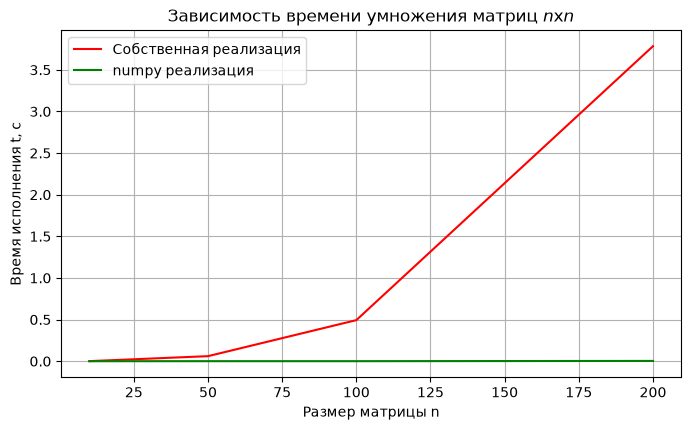

In [11]:
matmul_times = []
np_times = []
for d in test_history:
    matmul_times.append(d[1]['matmul()'])
    np_times.append(d[1]['@'])

plt.figure()
plt.plot(n_values, matmul_times, 'r-', label="Собственная реализация")
plt.plot(n_values, np_times, 'g-', label="numpy реализация")
plt.xlabel("Размер матрицы n")
plt.ylabel("Время исполнения t, с")
plt.title(r"Зависимость времени умножения матриц $n$x$n$")
plt.grid(True)
plt.legend()
plt.show()

## Исследование плохо обусловленной матрицы

Рассмотреть матрицу Гильберта $H_{10}$.

Исследовать число обусловленности (чем ближе к 1, тем более обусловлена) и связь с ошибкой восстановления:

$$||AH^{-1}-E||$$

Сделать вывод о чувствительности вычислений.

In [12]:
def create_hilbert_matrix(n):
    # return np.array([[1 / (i + j - 1) for j in range(1, n + 1)] for i in range(1, n + 1)])   
    return np.fromfunction(lambda i, j: 1 / ((i + 1) + (j + 1) - 1), (n, n))

In [13]:
H = create_hilbert_matrix(10)
# TODO: Взять некий массив dx и делать A = H + dx и провять с обратной inverse(H)

cond_H = np.linalg.cond(H) # Число обусловленности
H_inv = inverse(H, -np.inf)

err_own = np.linalg.norm(H @ H_inv - np.eye(10))
err_np = np.linalg.norm(H @ np.linalg.inv(H) - np.eye(10))

print("Число обусловленности: ", cond_H)
print(f"Ошибка восстановления собственной реализации: {err_own:.8f}")
print(f"Ошибка восстановления библиотечкной реализации: {err_np:.8f}")

Число обусловленности:  16024949194979.473
Ошибка восстановления собственной реализации: 0.00889129
Ошибка восстановления библиотечкной реализации: 0.00015651


***Вывод:*** Ошибка восстановления собственного метода в 1000 раз больше, чем у библиотечного метода